In [ ]:
import copy
import gc
import logging
import random
from pathlib import Path

import numpy as np
import pandas as pd
import pywt
from scipy import signal
from scipy.ndimage import uniform_filter1d
from sklearn import metrics
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

BASE_DIR      = Path('data')
RAW_TRAIN_DIR = BASE_DIR / 'train'
RAW_TEST_DIR  = BASE_DIR / 'test'
PROC_DIR      = BASE_DIR / 'processed'
PROC_DIR.mkdir(parents=True, exist_ok=True)

NUM_SUBJ    = 12
NUM_SERIES  = 8
SAMPLING_RATE = 500

WINDOW_SIZE     = 5000
TRAIN_BATCH     = 25  
NEPOCHS         = 1000
EVAL_EVERY      = 25
EARLY_STOP_PAT  = 10
LR              = 0.00175
SOFT_LABEL_FLOOR = 0.05
RANDOM_SEED     = 42

EEG_COLS = [
    'Fp1','Fp2','F7','F3','Fz','F4','F8',
    'FC5','FC1','FC2','FC6',
    'T7','C3','Cz','C4','T8',
    'TP9','CP5','CP1','CP2','CP6','TP10',
    'P7','P3','Pz','P4','P8',
    'PO9','O1','Oz','O2','PO10',
]
EVENT_COLS = [
    'HandStart','FirstDigitTouch','BothStartLoadPhase',
    'LiftOff','Replace','BothReleased',
]

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
if torch.cuda.is_available():
    print('GPU   :', torch.cuda.get_device_name(0))
    print('VRAM  :', round(torch.cuda.get_device_properties(0).total_memory/1024**3,1), 'GB')


Device: cuda
GPU   : NVIDIA GeForce RTX 4070 Laptop GPU
VRAM  : 8.0 GB


## Step 1 — Preprocessing: wavelet denoising

Preprocessing steps applied once and cached to `.npy`:
1. Wavelet decompose each channel (db2, level 3, periodic padding)
2. Estimate noise via MAD of finest-level coefficients
3. Apply universal hard threshold
4. Reconstruct


In [2]:
def madev(d, axis=None):
    return np.mean(np.abs(d - np.mean(d, axis=axis)), axis=axis)


def wavelet_denoise_array(x, wavelet='db2', level=3):
    """
    x : (n_samples, n_channels) float32
    Returns denoised array of same shape.
    """
    out = np.empty_like(x)
    for ch in range(x.shape[1]):
        sig = x[:, ch].astype(np.float64)
        coeff = pywt.wavedec(sig, wavelet, mode='per')
        sigma = (1.0 / 0.6745) * madev(coeff[-level])
        uthresh = sigma * np.sqrt(2 * np.log(len(sig)))
        coeff[1:] = [pywt.threshold(c, value=uthresh, mode='hard') for c in coeff[1:]]
        out[:, ch] = pywt.waverec(coeff, wavelet, mode='per')[:len(sig)].astype(np.float32)
    return out


def load_and_denoise(subject_id, series_id, raw_dir):
    """
    Reads one subject/series pair, denoises, returns (X, y) numpy arrays.
    X : (n, 32) float32
    y : (n, 6)  uint8
    """
    data_path  = raw_dir / f'subj{subject_id}_series{series_id}_data.csv'
    event_path = raw_dir / f'subj{subject_id}_series{series_id}_events.csv'

    x_df = pd.read_csv(data_path,  usecols=EEG_COLS)
    y_df = pd.read_csv(event_path, usecols=EVENT_COLS)

    x = x_df.to_numpy(dtype=np.float32)
    y = y_df.to_numpy(dtype=np.uint8)

    x = wavelet_denoise_array(x)
    n = min(len(x), len(y))
    return x[:n], y[:n]


def preprocess_and_cache(num_subj, num_series, raw_dir, out_dir, overwrite=False):
    out_dir.mkdir(parents=True, exist_ok=True)
    manifest = []

    for subj in range(1, num_subj + 1):
        for ser in tqdm(range(1, num_series + 1),
                        desc=f'Preprocess subj {subj}', leave=False):
            xp = out_dir / f'subj{subj}_s{ser}_X.npy'
            yp = out_dir / f'subj{subj}_s{ser}_y.npy'

            if xp.exists() and yp.exists() and not overwrite:
                X = np.load(xp, mmap_mode='r')
                manifest.append(dict(subj=subj, ser=ser,
                                     xp=str(xp), yp=str(yp),
                                     n=X.shape[0], status='cached'))
                continue

            try:
                X, y = load_and_denoise(subj, ser, raw_dir)
                np.save(xp, X)
                np.save(yp, y)
                manifest.append(dict(subj=subj, ser=ser,
                                     xp=str(xp), yp=str(yp),
                                     n=X.shape[0], status='processed'))
                del X, y; gc.collect()
            except FileNotFoundError as e:
                logging.warning(str(e))

    return pd.DataFrame(manifest)


manifest = preprocess_and_cache(NUM_SUBJ, NUM_SERIES, RAW_TRAIN_DIR, PROC_DIR)
print(manifest.groupby('status')['n'].agg(['count','sum']))
display(manifest.head())


        count       sum
status                 
cached     96  17985754


,subj,ser,xp,yp,n,status
0,1,1,data\processed\subj1_s1_X.npy,data\processed\subj1_s1_y.npy,119496,cached
1,1,2,data\processed\subj1_s2_X.npy,data\processed\subj1_s2_y.npy,271954,cached
2,1,3,data\processed\subj1_s3_X.npy,data\processed\subj1_s3_y.npy,217614,cached
3,1,4,data\processed\subj1_s4_X.npy,data\processed\subj1_s4_y.npy,116240,cached
4,1,5,data\processed\subj1_s5_X.npy,data\processed\subj1_s5_y.npy,210644,cached


## Step 2 — Fit StandardScaler on training data only
We scale *after* wavelet denoising. The scaler is fitted only on train subjects to avoid any data leakage into val/test.


In [3]:
subjects     = sorted(manifest['subj'].unique())
test_subjs   = [subjects[-1]]
val_subjs    = [subjects[-2]]
train_subjs  = [s for s in subjects if s not in test_subjs + val_subjs]

print('Train subjects:', train_subjs)
print('Val subjects  :', val_subjs)
print('Test subjects :', test_subjs)

def fit_scaler(manifest, train_subjs):
    scaler = StandardScaler()
    rows = manifest[manifest['subj'].isin(train_subjs)]
    for _, row in tqdm(rows.iterrows(), total=len(rows), desc='Fitting scaler'):
        X = np.load(row['xp'], mmap_mode='r')
        scaler.partial_fit(X)
        del X
    mean  = scaler.mean_.astype(np.float32)
    scale = np.where(scaler.scale_ > 0, scaler.scale_, 1.0).astype(np.float32)
    return mean, scale


scaler_path = PROC_DIR / 'scaler.npz'
if scaler_path.exists():
    d = np.load(scaler_path)
    sc_mean, sc_scale = d['mean'], d['scale']
    print('Loaded cached scaler.')
else:
    sc_mean, sc_scale = fit_scaler(manifest, train_subjs)
    np.savez(scaler_path, mean=sc_mean, scale=sc_scale)
    print('Scaler fitted and cached.')

print('mean shape:', sc_mean.shape)


Train subjects: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
Val subjects  : [np.int64(11)]
Test subjects : [np.int64(12)]
Loaded cached scaler.
mean shape: (32,)


## Step 3 — Load all series into memory (scaled)
The UNet processes full raw series in one pass (chunked to 10 000 samples at inference). At training we random-crop 5000-sample windows. Loading into RAM avoids repeated disk reads.
If RAM is tight, reduce `NUM_SUBJ` or skip scaling and let the Dataset do it lazily.


In [4]:
def load_split(manifest, subjs, sc_mean, sc_scale):
    xs, ys = [], []
    rows = manifest[manifest['subj'].isin(subjs)].sort_values(['subj','ser'])
    for _, row in tqdm(rows.iterrows(), total=len(rows),
                       desc=f'Loading {subjs}'):
        X = np.load(row['xp']).astype(np.float32)
        y = np.load(row['yp']).astype(np.float32)
        X = (X - sc_mean) / sc_scale   # scale in-place equivalent
        xs.append(X)
        ys.append(y)
    return xs, ys


xs_train, ys_train = load_split(manifest, train_subjs, sc_mean, sc_scale)
xs_val,   ys_val   = load_split(manifest, val_subjs,   sc_mean, sc_scale)
xs_test,  ys_test  = load_split(manifest, test_subjs,  sc_mean, sc_scale)

print(f'Train series: {len(xs_train)}  |  '
      f'Val: {len(xs_val)}  |  Test: {len(xs_test)}')
print(f'Example train shape: {xs_train[0].shape}  labels: {ys_train[0].shape}')


Loading [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]: 100%|██████████| 80/80 [00:01<00:00, 41.59it/s]
Loading [np.int64(12)]: 100%|██████████| 8/8 [00:00<00:00, 37.28it/s]

Train series: 80  |  Val: 8  |  Test: 8
Example train shape: (119496, 32)  labels: (119496, 6)


## Step 4 — Dataset with event-density-weighted sampling + soft labels

**Event-density-weighted sampling** we compute `p ∝ (event_present * 5 + 1)` for every possible window start position, then draw from that distribution. Regions where events occur are sampled 6× more often than pure-negative regions, and critically, *transition zones* around event boundaries are sampled proportionally — which is exactly where the classifier needs to be most precise.

**Soft labels** `label[label < 0.05] = 0.05`: the model never sees an exact 0. Because EEG event onsets are fuzzy (the annotation marks a keyframe, not the actual cortical preparation start), hard 0s in the surrounding samples mislead training. A floor of 0.05 acts as gentle label smoothing on the negative class only.

**Segmentation target**: `__getitem__` returns `(channels, time)` EEG and `(6_events, time)` mask — not a single label vector. The UNet is trained to output a probability trace for every timestep.


In [ ]:
class EEGSegDataset(Dataset):
    """
    Segmentation dataset.
    Returns:
        eeg  : (32, window_size) float32
        mask : (6,  window_size) float32  -- soft labels
    """
    def __init__(self, xs, ys, window_size=5000,
                 train=True, soft_label_floor=0.05, seed=42):
        self.xs           = xs
        self.ys           = ys
        self.window_size  = window_size
        self.train        = train
        self.soft_floor   = soft_label_floor
        self.rng          = np.random.default_rng(seed)

    def __len__(self):
        return len(self.xs)

    def __getitem__(self, idx):
        eeg  = self.xs[idx]   # (n, 32)
        mask = self.ys[idx]   # (n, 6)
        n    = eeg.shape[0]
        size = self.window_size

        if self.train:
            # Event-density-weighted sampling (reference notebook strategy)
            # smask[t] = 1 if any event is active at t, else 0
            usable = max(n - size, 1)
            smask = (mask[:usable].sum(axis=1) > 0).astype(np.float32)
            p = smask * 5.0 + 1.0          # event windows 6x more likely
            p = p / p.sum()
            start = self.rng.choice(usable, p=p)
        else:
            start = 0   # val/test: always from the beginning (chunked at inference)

        eeg_w  = eeg[start : start + size]   # (size, 32)
        mask_w = mask[start : start + size]  # (size, 6)

        # Pad if series is shorter than window_size
        pad = size - eeg_w.shape[0]
        if pad > 0:
            eeg_w  = np.pad(eeg_w,  ((0, pad), (0, 0)))
            mask_w = np.pad(mask_w, ((0, pad), (0, 0)))

        # Soft labels: prevent over-confident zeros on neg samples
        if self.train:
            mask_w = mask_w.copy().astype(np.float32)
            mask_w[mask_w < self.soft_floor] = self.soft_floor

        # (time, ch) -> (ch, time) for Conv1d
        return (torch.from_numpy(eeg_w.T.copy()),
                torch.from_numpy(mask_w.T.copy()))


train_dataset = EEGSegDataset(xs_train, ys_train, window_size=WINDOW_SIZE,
                               train=True,  soft_label_floor=SOFT_LABEL_FLOOR,
                               seed=RANDOM_SEED)
val_dataset   = EEGSegDataset(xs_val,   ys_val,   window_size=WINDOW_SIZE,
                               train=False, seed=RANDOM_SEED)

train_loader = DataLoader(train_dataset, batch_size=TRAIN_BATCH,
                           num_workers=0, shuffle=True,
                           pin_memory=torch.cuda.is_available())

val_loader   = DataLoader(val_dataset,   batch_size=1,
                           num_workers=0, shuffle=False)

print(f'Train batches/epoch: {len(train_loader)}')
# Smoke test
xb, yb = next(iter(train_loader))
print(f'Batch EEG shape : {tuple(xb.shape)}   (batch, channels, time)')
print(f'Batch mask shape: {tuple(yb.shape)}   (batch, events,   time)')


Train batches/epoch: 4
Batch EEG shape : (25, 32, 5000)   (batch, channels, time)
Batch mask shape: (25, 6, 5000)   (batch, events,   time)


## Step 5 — UNet with EfficientNet-B1 encoder

- Encoder compresses the 5000-sample signal through a pretrained feature hierarchy
- Decoder upsamples back to the original length via skip connections so every output timestep has access to both local detail (from skip) and global context (from bottleneck)
- The model outputs `(batch, 6, 5000)` "a probability trace" which is  matching the competition's per-sample evaluation
- No stride-1 sliding window needed at inference; one forward pass covers the whole series (chunked to 10 000 samples)

We use `nnspt` which wraps `timm` EfficientNet weights into a 1-D UNet. If `nnspt` is not available we fall back to a lightweight 1-D UNet built from scratch (Not recommended)

Run below to use pretrained model:
- %pip install git+https://github.com/rostepifanov/nnspt@release_v0.0.2
- %pip install timm


In [6]:
def build_model(n_channels=32, n_classes=6):
    """
    Try nnspt UNet with EfficientNet-B1 encoder (reference notebook).
    Falls back to a pure-PyTorch 1-D UNet if nnspt is not installed.
    """
    try:
        from nnspt.segmentation.unet import Unet
        model = Unet(in_channels=n_channels, out_channels=n_classes,
                     encoder='timm-efficientnet-b1')
        print('Using nnspt UNet + EfficientNet-B1 encoder (pretrained)')
        return model
    except ImportError:
        print('nnspt not found -- using fallback 1-D UNet (no pretrained encoder)')
        return UNet1D(n_channels, n_classes)


# ---- Fallback: lightweight 1-D UNet ----------------------------------------
class ConvBlock1D(nn.Module):
    def __init__(self, in_ch, out_ch, kernel=7, dropout=0.2):
        super().__init__()
        p = kernel // 2
        self.net = nn.Sequential(
            nn.Conv1d(in_ch,  out_ch, kernel, padding=p, bias=False),
            nn.BatchNorm1d(out_ch), nn.GELU(),
            nn.Dropout(dropout),
            nn.Conv1d(out_ch, out_ch, kernel, padding=p, bias=False),
            nn.BatchNorm1d(out_ch), nn.GELU(),
        )
        self.proj = nn.Conv1d(in_ch, out_ch, 1, bias=False) if in_ch != out_ch else nn.Identity()

    def forward(self, x):
        return self.net(x) + self.proj(x)


class UNet1D(nn.Module):
    """
    Lightweight 1-D UNet fallback.
    Input : (B, C, T)
    Output: (B, n_classes, T)  -- raw logits
    """
    def __init__(self, in_ch=32, n_classes=6, base=64, depth=4, dropout=0.2):
        super().__init__()
        chs = [base * (2 ** i) for i in range(depth + 1)]

        # Encoder
        self.enc = nn.ModuleList()
        self.pool = nn.ModuleList()
        prev = in_ch
        for ch in chs[:-1]:
            self.enc.append(ConvBlock1D(prev, ch, dropout=dropout))
            self.pool.append(nn.MaxPool1d(2))
            prev = ch

        # Bottleneck
        self.bottleneck = ConvBlock1D(prev, chs[-1], dropout=dropout)

        # Decoder
        self.up   = nn.ModuleList()
        self.dec  = nn.ModuleList()
        for ch_skip, ch_up in zip(reversed(chs[:-1]), reversed(chs[1:])):
            self.up.append(nn.ConvTranspose1d(ch_up, ch_skip, kernel_size=2, stride=2))
            self.dec.append(ConvBlock1D(ch_skip * 2, ch_skip, dropout=dropout))

        self.head = nn.Conv1d(chs[0], n_classes, 1)

    def forward(self, x):
        skips = []
        for enc, pool in zip(self.enc, self.pool):
            x = enc(x)
            skips.append(x)
            x = pool(x)
        x = self.bottleneck(x)
        for up, dec, skip in zip(self.up, self.dec, reversed(skips)):
            x = up(x)
            # Handle odd-length mismatches
            if x.shape[-1] != skip.shape[-1]:
                x = F.interpolate(x, size=skip.shape[-1])
            x = dec(torch.cat([skip, x], dim=1))
        return self.head(x)


model = build_model(n_channels=len(EEG_COLS), n_classes=len(EVENT_COLS)).to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable parameters: {n_params:,}')


Using nnspt UNet + EfficientNet-B1 encoder (pretrained)
Trainable parameters: 6,881,940


## Step 6 — Training with AUC-based early stopping



In [7]:
def evaluate_val(model, xs_val, ys_val, device, chunk_size=10000):
    """
    Full-series inference on validation subjects.
    Runs the model over each series in non-overlapping chunks of `chunk_size`
    samples and concatenates the per-sample probabilities.
    Returns macro AUC.
    """
    model.eval()
    y_pred_all, y_true_all = [], []

    for X, y in zip(xs_val, ys_val):
        # X: (n, 32)  y: (n, 6)
        n = X.shape[0]
        probs_chunks = []

        for start in range(0, n, chunk_size):
            Xb = X[start : start + chunk_size]   # (chunk, 32)
            Xt = torch.from_numpy(Xb.T[None]).to(device)  # (1, 32, chunk)
            with torch.no_grad():
                logits = model(Xt)
                probs  = torch.sigmoid(logits).cpu().numpy()[0]  # (6, chunk)
            probs_chunks.append(probs)

        probs_series = np.concatenate(probs_chunks, axis=1).T  # (n, 6)
        y_pred_all.append(probs_series)
        y_true_all.append(y.astype(np.float32))

    y_pred = np.concatenate(y_pred_all, axis=0)
    y_true = np.concatenate(y_true_all, axis=0)

    auc_per_event = {}
    for i, ev in enumerate(EVENT_COLS):
        try:
            auc_per_event[ev] = metrics.roc_auc_score(y_true[:, i], y_pred[:, i])
        except ValueError:
            auc_per_event[ev] = float('nan')

    macro_auc = np.nanmean(list(auc_per_event.values()))
    return macro_auc, auc_per_event, y_pred, y_true


optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=NEPOCHS * len(train_loader),  # steps over full training run
    eta_min=1e-6,
)

best_auc        = 0.0
best_state_dict = copy.deepcopy(model.state_dict())
best_model_path = 'best_unet_eeg.pt'
history         = []
patience_count  = 0
train_loss_buf  = []

print(f'Training for up to {NEPOCHS} epochs, '
      f'evaluating every {EVAL_EVERY}, '
      f'early stopping patience = {EARLY_STOP_PAT} evaluations '
      f'(= {EARLY_STOP_PAT * EVAL_EVERY} epochs)')


Training for up to 1000 epochs, evaluating every 25, early stopping patience = 10 evaluations (= 250 epochs)


In [8]:
for epoch in range(1, NEPOCHS + 1):
    model.train()
    epoch_loss = 0.0

    for eeg_batch, mask_batch in train_loader:
        eeg_batch  = eeg_batch.to(device,  non_blocking=True)
        mask_batch = mask_batch.to(device, non_blocking=True)

        logits = model(eeg_batch)

        # Resize logits to match mask if UNet changes the length slightly
        if logits.shape[-1] != mask_batch.shape[-1]:
            logits = F.interpolate(logits, size=mask_batch.shape[-1])

        loss = F.binary_cross_entropy_with_logits(logits, mask_batch)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        optimizer.step()
        scheduler.step()   # per-batch step
        optimizer.zero_grad(set_to_none=True)

        epoch_loss += loss.item()
        train_loss_buf.append(loss.item())

    # ---- Periodic evaluation -----------------------------------------------
    if epoch % EVAL_EVERY == 0:
        mean_loss = np.mean(train_loss_buf)
        train_loss_buf.clear()

        macro_auc, auc_per_ev, _, _ = evaluate_val(
            model, xs_val, ys_val, device)

        history.append(dict(epoch=epoch, train_loss=mean_loss,
                            val_auc=macro_auc))

        print(f'[{epoch:4d}/{NEPOCHS}]  '
              f'loss={mean_loss:.4f}  val_AUC={macro_auc:.4f}  '
              f'lr={scheduler.get_last_lr()[0]:.2e}')
        print('  per-event:', {k: round(v,3) for k,v in auc_per_ev.items()})

        if macro_auc > best_auc:
            best_auc = macro_auc
            best_state_dict = copy.deepcopy(model.state_dict())
            torch.save(best_state_dict, best_model_path)
            print(f'  >>> New best val AUC: {best_auc:.4f} -- saved.')
            patience_count = 0
        else:
            patience_count += 1
            print(f'  No improvement. Patience {patience_count}/{EARLY_STOP_PAT}')
            if patience_count >= EARLY_STOP_PAT:
                print(f'Early stopping at epoch {epoch}. '
                      f'Best val AUC = {best_auc:.4f}')
                break

# Restore best weights
model.load_state_dict(best_state_dict)
print(f'\nTraining complete. Best val AUC: {best_auc:.4f}')


[  25/1000]  loss=0.3357  val_AUC=0.5608  lr=1.75e-03
  per-event: {'HandStart': 0.638, 'FirstDigitTouch': 0.491, 'BothStartLoadPhase': 0.521, 'LiftOff': 0.524, 'Replace': 0.589, 'BothReleased': 0.602}
  >>> New best val AUC: 0.5608 -- saved.
[  50/1000]  loss=0.2718  val_AUC=0.5822  lr=1.74e-03
  per-event: {'HandStart': 0.692, 'FirstDigitTouch': 0.497, 'BothStartLoadPhase': 0.529, 'LiftOff': 0.533, 'Replace': 0.627, 'BothReleased': 0.616}
  >>> New best val AUC: 0.5822 -- saved.
[  75/1000]  loss=0.2711  val_AUC=0.6039  lr=1.73e-03
  per-event: {'HandStart': 0.709, 'FirstDigitTouch': 0.512, 'BothStartLoadPhase': 0.544, 'LiftOff': 0.56, 'Replace': 0.649, 'BothReleased': 0.65}
  >>> New best val AUC: 0.6039 -- saved.
[ 100/1000]  loss=0.2701  val_AUC=0.6113  lr=1.71e-03
  per-event: {'HandStart': 0.727, 'FirstDigitTouch': 0.51, 'BothStartLoadPhase': 0.539, 'LiftOff': 0.579, 'Replace': 0.669, 'BothReleased': 0.645}
  >>> New best val AUC: 0.6113 -- saved.
[ 125/1000]  loss=0.2711  val_A

## Step 7 — Full evaluation on val and test sets

In [9]:
history_df = pd.DataFrame(history)
print('Training history:')
display(history_df)

# ---- Val evaluation (best weights) ----------------------------------------
print('\n--- Validation set ---')
val_auc, val_auc_per_ev, val_pred, val_true = evaluate_val(
    model, xs_val, ys_val, device)
print(f'Val macro AUC: {val_auc:.4f}')
print(pd.Series(val_auc_per_ev, name='AUC').round(4).to_string())

# ---- Test evaluation -------------------------------------------------------
print('\n--- Test set ---')
test_auc, test_auc_per_ev, test_pred, test_true = evaluate_val(
    model, xs_test, ys_test, device)
print(f'Test macro AUC: {test_auc:.4f}')
print(pd.Series(test_auc_per_ev, name='AUC').round(4).to_string())

# ---- Classification report (with 0.5 threshold for reference) --------------
from sklearn.metrics import classification_report
y_pred_bin = (test_pred >= 0.5).astype(int)
print('\nClassification report (threshold=0.5):')
print(classification_report(test_true, y_pred_bin,
                             target_names=EVENT_COLS, zero_division=0))


Training history:


,epoch,train_loss,val_auc
0,25,0.335693,0.560810
1,50,0.271808,0.582233
2,75,0.271117,0.603869
3,100,0.270106,0.611313
4,125,0.271140,0.619538
5,150,0.270586,0.626803
6,175,0.270131,0.633797
7,200,0.267135,0.638033
8,225,0.267668,0.653989
9,250,0.266632,0.705307



--- Validation set ---
Val macro AUC: 0.8041
HandStart             0.8329
FirstDigitTouch       0.8243
BothStartLoadPhase    0.8130
LiftOff               0.7920
Replace               0.8048
BothReleased          0.7574

--- Test set ---
Test macro AUC: 0.8242
HandStart             0.8509
FirstDigitTouch       0.8561
BothStartLoadPhase    0.8666
LiftOff               0.8489
Replace               0.7855
BothReleased          0.7374

Classification report (threshold=0.5):
                    precision    recall  f1-score   support

         HandStart       0.44      0.16      0.24     39000
   FirstDigitTouch       0.23      0.05      0.09     39000
BothStartLoadPhase       0.26      0.08      0.12     39000
           LiftOff       0.22      0.01      0.03     39000
           Replace       0.29      0.08      0.12     39000
      BothReleased       0.18      0.03      0.06     39000

         micro avg       0.29      0.07      0.11    234000
         macro avg       0.27      0.07    

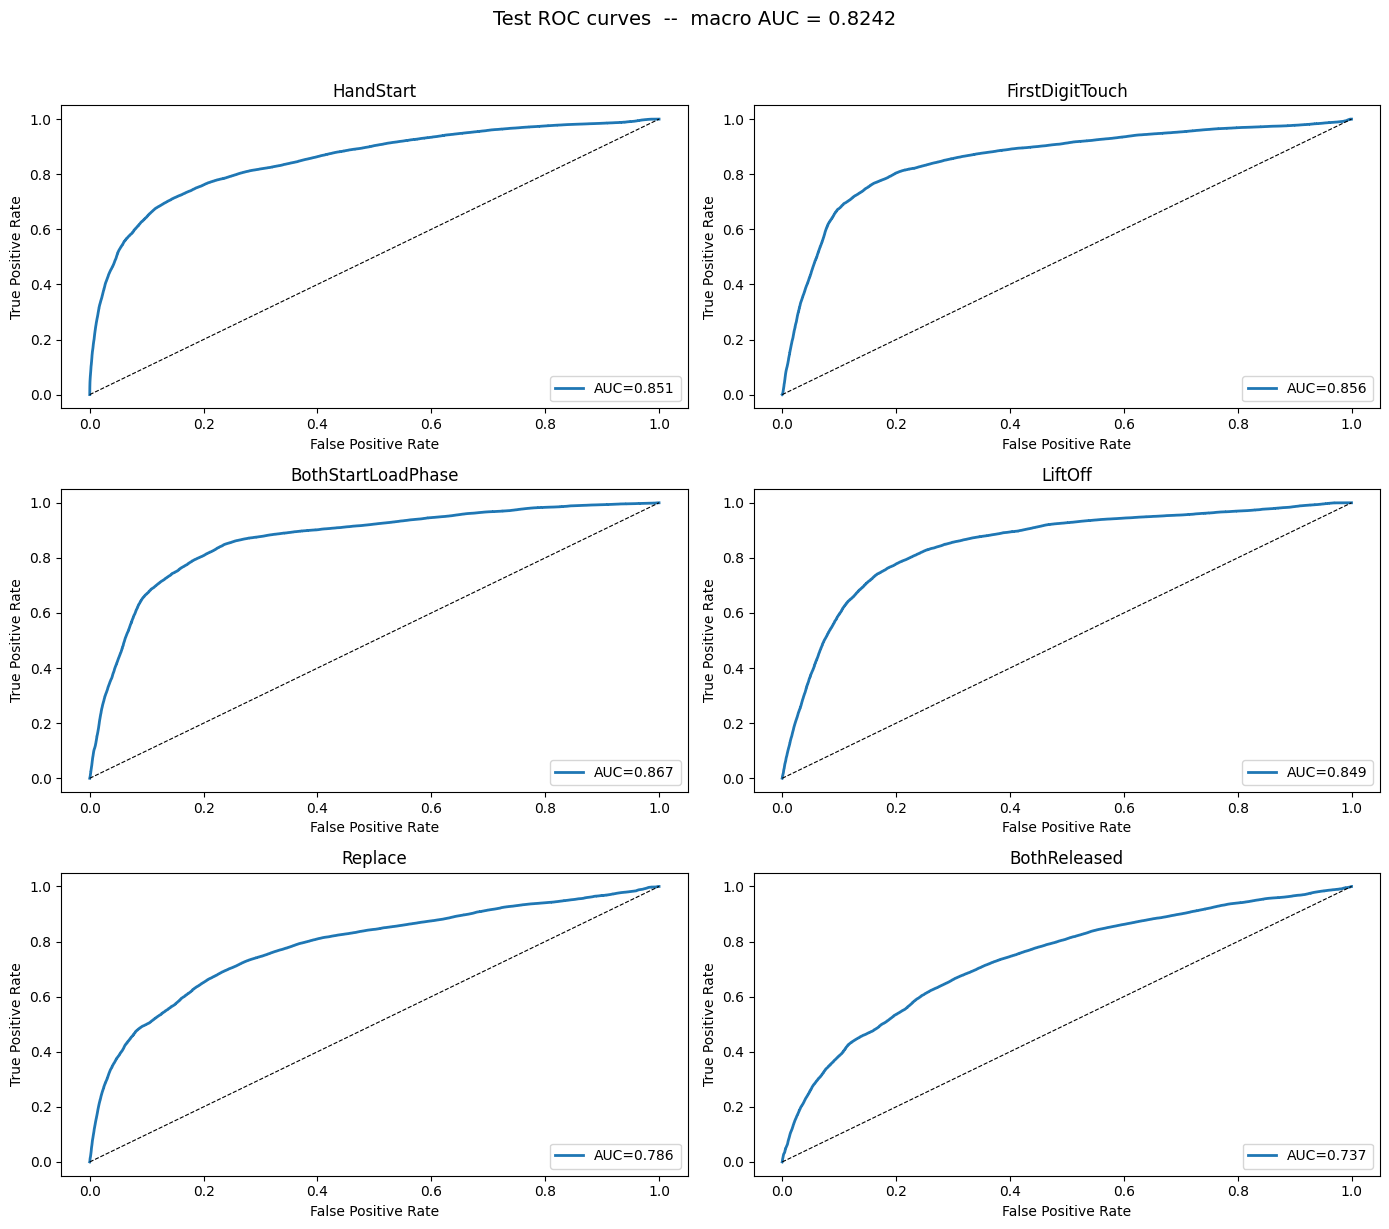

In [11]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(3, 2, figsize=(14, 12))
for i, ev in enumerate(EVENT_COLS):
    fpr, tpr, _ = metrics.roc_curve(test_true[:, i], test_pred[:, i])
    ax = axs[i // 2, i % 2]
    ax.plot(fpr, tpr, linewidth=2,
            label=f'AUC={test_auc_per_ev[ev]:.3f}')
    ax.plot([0, 1], [0, 1], 'k--', linewidth=0.8)
    ax.set_title(ev)
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.legend(loc='lower right')

plt.suptitle(f'Test ROC curves  --  macro AUC = {test_auc:.4f}',
             fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('roc_curves_test.png', dpi=120, bbox_inches='tight')
plt.show()


## Step 8 — Generate Kaggle submission
The UNet outputs dense per-sample predictions natively, so no sliding-window inference is needed. We chunk each test series to 10 000 samples to fit in GPU memory.


In [12]:
SUBMIT_DIR = BASE_DIR / 'submissions'
SUBMIT_DIR.mkdir(exist_ok=True)

model.eval()

all_rows   = []
chunk_size = 10000

for subj in tqdm(range(1, NUM_SUBJ + 1), desc='Generating submission'):
    for series in [9, 10]:   # Kaggle test series
        data_path = RAW_TEST_DIR / f'subj{subj}_series{series}_data.csv'
        if not data_path.exists():
            continue

        # Load, denoise, scale
        X_raw = pd.read_csv(data_path, usecols=EEG_COLS).to_numpy(dtype=np.float32)
        X_den = wavelet_denoise_array(X_raw)
        X_sc  = (X_den - sc_mean) / sc_scale   # (n, 32)
        n     = X_sc.shape[0]

        probs_chunks = []
        for start in range(0, n, chunk_size):
            Xb = X_sc[start : start + chunk_size]
            Xt = torch.from_numpy(Xb.T[None]).to(device)
            with torch.no_grad():
                logits = model(Xt)
                probs  = torch.sigmoid(logits).cpu().numpy()[0]  # (6, chunk)
            probs_chunks.append(probs)

        probs_series = np.concatenate(probs_chunks, axis=1).T[:n]  # (n, 6)

        # Build submission rows
        ids = [f'subj{subj}_series{series}_{t}' for t in range(n)]
        df_chunk = pd.DataFrame(probs_series, columns=EVENT_COLS)
        df_chunk.insert(0, 'id', ids)
        all_rows.append(df_chunk)

if all_rows:
    submission = pd.concat(all_rows, ignore_index=True)
    out_path = SUBMIT_DIR / 'submission.csv'
    submission.to_csv(out_path, index=False, float_format='%.4f')
    print(f'Submission saved to {out_path}  ({len(submission):,} rows)')
    display(submission.head())
else:
    print('No test files found in', RAW_TEST_DIR)
    print('Set RAW_TEST_DIR = BASE_DIR / "test" and place the Kaggle test CSVs there.')


Generating submission: 100%|██████████| 12/12 [00:14<00:00,  1.22s/it]


Submission saved to data\submissions\submission.csv  (3,144,171 rows)


,id,HandStart,FirstDigitTouch,BothStartLoadPhase,LiftOff,Replace,BothReleased
0,subj1_series9_0,0.251236,0.211162,0.275808,0.159623,0.131498,0.182398
1,subj1_series9_1,0.292745,0.091796,0.097146,0.064637,0.073564,0.064564
2,subj1_series9_2,0.333468,0.097165,0.090980,0.047734,0.050213,0.050070
3,subj1_series9_3,0.332497,0.119081,0.097361,0.042880,0.048698,0.040312
4,subj1_series9_4,0.401716,0.136968,0.118357,0.051312,0.054479,0.040894


# Kaggle Submission:
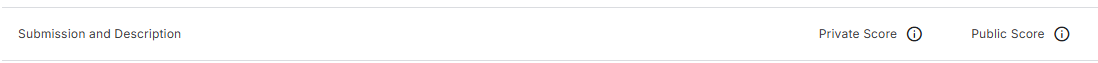
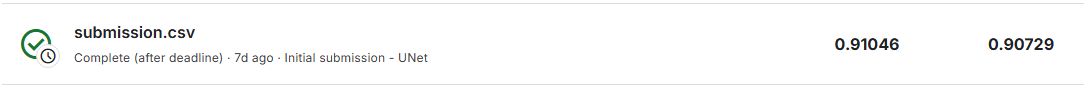